In [15]:
pip install numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 7.5 MB/s eta 0:00:0000:0100:01


In [1]:
import json
import os
import numpy as np

In [ ]:
def get_structure(data, indent=0, parent_key='root'):
    prefix = '  ' * indent
    if isinstance(data, dict):
        print(f"{prefix}{parent_key} (dict):")
        for key, value in data.items():
            get_structure(value, indent + 1, key)
    elif isinstance(data, list):
        print(f"{prefix}{parent_key} (list, length={len(data)})")
        if data:
            if all(isinstance(i, list) for i in data):
                print(f"{prefix}  -> list of lists:")
                for i, sublist in enumerate(data):
                    if isinstance(sublist, list):
                        print(f"{prefix}    [{i}]: list, length={len(sublist)}")
                        if sublist and isinstance(sublist[0], dict):
                            print(f"{prefix}      -> contains dicts:")
                            for j, subdict in enumerate(sublist):
                                if isinstance(subdict, dict):
                                    get_structure(subdict, indent + 4, f"{parent_key}[{i}][{j}]")
            elif all(isinstance(i, dict) for i in data):
                print(f"{prefix}  -> list of dicts:")
                for i, item in enumerate(data):
                    get_structure(item, indent + 2, f"{parent_key}[{i}]")
            else:
                print(f"{prefix}  -> list of {type(data[0]).__name__}")
    else:
        print(f"{prefix}{parent_key} ({type(data).__name__}): {str(data)[:50]}")


def read_json_and_describe_structure(filepath):
    if not os.path.exists(filepath):
        print(f"File not found: {filepath}")
        return

    with open(filepath, 'r', encoding='utf-8') as f:
        try:
            json_data = json.load(f)
        except json.JSONDecodeError as e:
            print(f"Failed to decode JSON: {e}")
            return

    print(f"Loaded JSON file: {filepath}\n")
    get_structure(json_data)

In [3]:
json_file_path = "/Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/results/json/DMO_eps_e1adamadapSAMconvmnist24-03-2024.json"

In [4]:
read_json_and_describe_structure(json_file_path)

✅ Loaded JSON file: /Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/results/json/DMO_eps_e1adamadapSAMconvmnist24-03-2024.json

root (dict):
  instances_loss_tr (list, length=10)
    -> list of lists:
      [0]: list, length=1000
      [1]: list, length=1000
      [2]: list, length=1000
      [3]: list, length=1000
      [4]: list, length=1000
      [5]: list, length=1000
      [6]: list, length=1000
      [7]: list, length=1000
      [8]: list, length=1000
      [9]: list, length=1000
  instances_loss_ts (list, length=10)
    -> list of lists:
      [0]: list, length=1000
      [1]: list, length=1000
      [2]: list, length=1000
      [3]: list, length=1000
      [4]: list, length=1000
      [5]: list, length=1000
      [6]: list, length=1000
      [7]: list, length=1000
      [8]: list, length=1000
      [9]: list, length=1000
  instances_acc_ts (list, length=10)
    -> list of lists:
      [0]: list, length=1000
      [1]: list, length=1000
      [2]: list, leng

In [5]:
with open(json_file_path, 'r', encoding='utf-8') as f:
    json_data = json.load(f)


In [6]:
json_data["max_loss_nghb_list"][0].keys()

dict_keys(['147'])

In [ ]:
def get_test_accuracy_at_convergence(json_path):
    with open(json_path, 'r') as f:
        data = json.load(f)

    acc_ts = data['instances_acc_ts']              # Test accuracy traces
    convergence_info = data['max_loss_nghb_list']  # Convergence iteration info

    acc_at_convergence = []

    for i in range(10):
        acc_instance = acc_ts[i]
        convergence_keys = convergence_info[i].keys()

        if not convergence_keys:
            print(f"No convergence key for instance {i}")
            acc_at_convergence.append(np.nan)
            continue

        # Get the final convergence iteration (largest key)
        conv_iter = max(map(int, convergence_keys))

        if conv_iter < len(acc_instance):
            acc = acc_instance[conv_iter]
            acc_at_convergence.append(acc)
        else:
            print(f"Convergence index {conv_iter} out of bounds for instance {i}")
            acc_at_convergence.append(np.nan)

    acc_array = np.array(acc_at_convergence)

    print("Test Accuracy at Convergence:")
    for i, acc in enumerate(acc_array):
        print(f"  Instance {i}: {acc:.4f}" if not np.isnan(acc) else f"  Instance {i}: NaN")

    print("\nStatistics:")
    print(f"  Mean Accuracy at Convergence: {np.nanmean(acc_array):.4f}")
    print(f"  Std Dev:                      {np.nanstd(acc_array):.4f}")



In [ ]:
def get_final_test_accuracy(json_path):
    with open(json_path, 'r') as f:
        data = json.load(f)

    acc_ts = data['instances_acc_ts']
    final_accuracies = []

    for i in range(10):
        acc_instance = acc_ts[i]
        if not acc_instance:
            print(f"Empty accuracy list for instance {i}")
            final_accuracies.append(np.nan)
            continue

        final_accuracies.append(acc_instance[-1])  # Last value

    final_array = np.array(final_accuracies)

    print("Final Test Accuracy at Last Iteration:")
    for i, acc in enumerate(final_array):
        print(f"  Instance {i}: {acc:.4f}" if not np.isnan(acc) else f"  Instance {i}: NaN")

    print("\nStatistics:")
    print(f"  Mean Final Accuracy: {np.nanmean(final_array):.4f}")
    print(f"  Std Dev:              {np.nanstd(final_array):.4f}")


In [9]:
print("=== Accuracy at Convergence ===")
get_test_accuracy_at_convergence(json_file_path)

print("\n=== Accuracy at Final Iteration ===")
get_final_test_accuracy(json_file_path)

=== Accuracy at Convergence ===
🎯 Test Accuracy at Convergence:
  Instance 0: 0.9375
  Instance 1: 0.9375
  Instance 2: 0.9531
  Instance 3: 0.9922
  Instance 4: 0.9922
  Instance 5: 0.0938
  Instance 6: 0.9453
  Instance 7: 0.9531
  Instance 8: 0.9219
  Instance 9: 0.9297

📊 Statistics:
  Mean Accuracy at Convergence: 0.8656
  Std Dev:                      0.2583

=== Accuracy at Final Iteration ===
📍 Final Test Accuracy at Last Iteration:
  Instance 0: 1.0000
  Instance 1: 1.0000
  Instance 2: 0.9844
  Instance 3: 1.0000
  Instance 4: 1.0000
  Instance 5: 0.1172
  Instance 6: 1.0000
  Instance 7: 1.0000
  Instance 8: 1.0000
  Instance 9: 1.0000

📊 Statistics:
  Mean Final Accuracy: 0.9102
  Std Dev:              0.2644


In [ ]:
def categorize_experiment_files(folder_path):
    datasets = ['fmnist', 'mnist', 'cifar']
    regularizers = ['adsam', 'gsam', 'sam', 'gam']

    # Architecture logic is more flexible
    arch_labels = ['mlp relu', 'mlp', 'conv']

    dataset_map = {ds: [] for ds in datasets}
    arch_map = {arch: [] for arch in arch_labels}
    reg_map = {reg: [] for reg in regularizers}
    unmatched = []

    all_files = [f for f in os.listdir(folder_path) if f.endswith('.json')]

    for file in all_files:
        file_lower = file.lower()
        matched = {'dataset': None, 'arch': None, 'reg': None}

        # Dataset
        for ds in datasets:
            if ds in file_lower:
                matched['dataset'] = ds
                dataset_map[ds].append(file)
                break

        # Architecture
        if 'mlp' in file_lower and 'relu' in file_lower:
            matched['arch'] = 'mlp relu'
            arch_map['mlp relu'].append(file)
        elif 'mlp' in file_lower:
            matched['arch'] = 'mlp'
            arch_map['mlp'].append(file)
        elif 'conv' in file_lower:
            matched['arch'] = 'conv'
            arch_map['conv'].append(file)

        # Regularizer (ordered to avoid substring conflicts)
        for reg in regularizers:
            if reg in file_lower:
                matched['reg'] = reg
                reg_map[reg].append(file)
                break

        if not all(matched.values()):
            unmatched.append((file, matched))

    # Display results
    print("Dataset-wise File Groups:")
    for ds, files in dataset_map.items():
        print(f"  {ds}: {len(files)} files")

    print("\nArchitecture-wise File Groups:")
    for arch, files in arch_map.items():
        print(f"  {arch}: {len(files)} files")

    print("\nRegularizer-wise File Groups:")
    for reg, files in reg_map.items():
        print(f"  {reg}: {len(files)} files")

    if unmatched:
        print("\nUnmatched or partially matched files:")
        for fname, parts in unmatched:
            missing = [k for k, v in parts.items() if v is None]
            print(f"  {fname} -> missing: {missing}")

    return dataset_map, arch_map, reg_map, unmatched



In [16]:
categorize_experiment_files("/Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/results/json/for_DMOptimizer")

📁 Dataset-wise File Groups:
  fmnist: 30 files
  mnist: 30 files
  cifar: 30 files

🧠 Architecture-wise File Groups:
  mlp relu: 30 files
  mlp: 30 files
  conv: 30 files

🧪 Regularizer-wise File Groups:
  adsam: 9 files
  gsam: 27 files
  sam: 9 files
  gam: 36 files

⚠️  Unmatched or partially matched files:
  DMO_eps__hyper_eps_meta_optim_convmnist0504dmo_cl_20HN_normalINIT_Adam001_021-04-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlp_Relumnist0504dmo_cl_20HN_normalINIT_Adam001_021-04-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlp_Relufmnist0504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlpcifar100504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_convfmnist0504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlp_Relucifar100504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json → missing: ['reg']

({'fmnist': ['DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistGSAM_sgd_LO_13042424-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_Relufmnist0504dmo_cl_20HN_normalINIT_Adam001_SAMonLOreg24-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_Relufmnist0504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlpfmnistAdSAM_sgd_LO_14042422-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_convfmnist0504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistAdSAM_sgd_LO_14042422-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_convfmnistAdSAM_sgd_LO_14042422-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistGSAM_sgd_LO_130424_122-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_convfmnistGAM_sgd_LO_12042425-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistGSAM_sgd_LO_130424_024-04-2024.json',
   'DMO_eps__hyper_eps_meta_optim_convfmnist0504dmo_cl_20HN_normalINIT_Adam001_SAMonLOreg25-04-202

In [17]:
categorize_experiment_files("/Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/results/json/for_DMO_optimizer_new_2")

📁 Dataset-wise File Groups:
  fmnist: 3 files
  mnist: 3 files
  cifar: 3 files

🧠 Architecture-wise File Groups:
  mlp relu: 3 files
  mlp: 3 files
  conv: 3 files

🧪 Regularizer-wise File Groups:
  adsam: 0 files
  gsam: 0 files
  sam: 0 files
  gam: 0 files

⚠️  Unmatched or partially matched files:
  DMO_eps__hyper_eps_meta_optim_mlpfmnistDMO_adam_280424_002-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlp_Relucifar10DMO_adam_280424_003-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_convmnistDMO_adam_280424_002-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistDMO_adam_280424_002-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlpmnistDMO_adam_280424_002-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_mlp_RelumnistDMO_adam_280424_002-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_optim_convcifar10DMO_adam_280424_003-05-2024.json → missing: ['reg']
  DMO_eps__hyper_eps_meta_opt

({'fmnist': ['DMO_eps__hyper_eps_meta_optim_mlpfmnistDMO_adam_280424_002-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistDMO_adam_280424_002-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_convfmnistDMO_adam_280424_003-05-2024.json'],
  'mnist': ['DMO_eps__hyper_eps_meta_optim_convmnistDMO_adam_280424_002-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlpmnistDMO_adam_280424_002-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelumnistDMO_adam_280424_002-05-2024.json'],
  'cifar': ['DMO_eps__hyper_eps_meta_optim_mlp_Relucifar10DMO_adam_280424_003-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_convcifar10DMO_adam_280424_003-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlpcifar10DMO_adam_280424_003-05-2024.json']},
 {'mlp relu': ['DMO_eps__hyper_eps_meta_optim_mlp_Relucifar10DMO_adam_280424_003-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelufmnistDMO_adam_280424_002-05-2024.json',
   'DMO_eps__hyper_eps_meta_optim_mlp_RelumnistDMO_adam_280424_002-05

In [ ]:
from collections import defaultdict

DATASETS = ['fmnist', 'mnist', 'cifar']
ARCHITECTURES = ['mlp relu', 'mlp', 'conv']
REGULARIZERS = ['adsam', 'gsam', 'sam', 'gam']

def parse_metadata(filename):
    name = filename.lower()
    dataset = next((ds for ds in DATASETS if ds in name), None)

    if 'mlp' in name and 'relu' in name:
        arch = 'mlp relu'
    elif 'mlp' in name:
        arch = 'mlp'
    elif 'conv' in name:
        arch = 'conv'
    else:
        arch = None

    reg = next((r for r in REGULARIZERS if r in name), None)
    return dataset, arch, reg

def get_test_accuracy_at_convergence(data):
    acc_ts = data.get('instances_acc_ts', [])
    conv_pts = data.get('max_loss_nghb_list', [])

    conv_accuracies = []
    for i in range(min(len(acc_ts), len(conv_pts))):
        acc_instance = acc_ts[i]
        conv_dict = conv_pts[i]
        if not conv_dict:
            continue
        conv_iter = max(map(int, conv_dict.keys()))
        if conv_iter < len(acc_instance):
            conv_accuracies.append(acc_instance[conv_iter])
    return conv_accuracies

def get_final_test_accuracy(data):
    acc_ts = data.get('instances_acc_ts', [])
    final_accuracies = [accs[-1] for accs in acc_ts if accs]
    return final_accuracies

def extract_accuracies(filepath):
    try:
        with open(filepath, 'r') as f:
            data = json.load(f)
    except Exception as e:
        print(f"Failed to load {filepath}: {e}")
        return None

    conv_acc = get_test_accuracy_at_convergence(data)
    final_acc = get_final_test_accuracy(data)

    return {
        "file": os.path.basename(filepath),
        "conv_mean": np.mean(conv_acc) if conv_acc else None,
        "conv_std": np.std(conv_acc) if conv_acc else None,
        "final_mean": np.mean(final_acc) if final_acc else None,
        "final_std": np.std(final_acc) if final_acc else None,
        "n_instances": len(final_acc),
    }

def process_folder(folder_path):
    results = defaultdict(list)
    all_files = [f for f in os.listdir(folder_path) if f.endswith('.json')]

    for fname in all_files:
        dataset, arch, reg = parse_metadata(fname)
        missing = []
        if not dataset: missing.append("dataset")
        if not arch: missing.append("architecture")
        if not reg: missing.append("regularizer")

        full_path = os.path.join(folder_path, fname)
        acc_info = extract_accuracies(full_path)

        if acc_info:
            key = (
                dataset if dataset else "UNKNOWN_DATASET",
                arch if arch else "UNKNOWN_ARCH",
                reg if reg else "UNKNOWN_REG"
            )
            acc_info["missing_tags"] = missing
            results[key].append(acc_info)

    return results

def print_summary(results):
    print("\nAccuracy Summary by Experiment Configuration:\n")
    for (dataset, arch, reg), files in sorted(results.items()):
        print(f"Dataset: {dataset} | Arch: {arch} | Reg: {reg}")
        for info in files:
            print(f"  {info['file']}")
            if info["missing_tags"]:
                print(f"     Missing tags: {', '.join(info['missing_tags'])}")
            if info["conv_mean"] is not None:
                print(f"     Convergence Accuracy: mean = {info['conv_mean']:.4f}, std = {info['conv_std']:.4f}")
                print(f"     Final Accuracy:       mean = {info['final_mean']:.4f}, std = {info['final_std']:.4f}")
            else:
                print(f"     Accuracy data missing or unreadable")
        print("")

In [29]:
folder = "/Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/results/json/for_DMOptimizer"
results = process_folder(folder)

In [30]:
print_summary(results)


📊 Accuracy Summary by Experiment Configuration:

📁 Dataset: cifar | Arch: conv | Reg: UNKNOWN_REG
  🔹 DMO_eps__hyper_eps_meta_optim_convcifar100504dmo_cl_20HN_normalINIT_Adam001_022-04-2024.json
     ⚠️ Missing tags: regularizer
     ↳ Convergence Accuracy: mean = 0.5750, std = 0.0618
     ↳ Final Accuracy:       mean = 0.5750, std = 0.0255

📁 Dataset: cifar | Arch: conv | Reg: adsam
  🔹 DMO_eps__hyper_eps_meta_optim_convcifar10AdSAM_sgd_LO_14042422-04-2024.json
     ↳ Convergence Accuracy: mean = 0.2797, std = 0.0500
     ↳ Final Accuracy:       mean = 0.1703, std = 0.0787

📁 Dataset: cifar | Arch: conv | Reg: gam
  🔹 DMO_eps__hyper_eps_meta_optim_convcifar10GAM_sgd_LO_12042425-04-2024.json
     ↳ Convergence Accuracy: mean = 0.1719, std = 0.0759
     ↳ Final Accuracy:       mean = 0.1094, std = 0.0164
  🔹 DMO_eps__hyper_eps_meta_optim_convcifar10GAM_sgd_LO_120424_024-04-2024.json
     ↳ Convergence Accuracy: mean = 0.1187, std = 0.0310
     ↳ Final Accuracy:       mean = 0.1094, std

In [25]:
%pwd

'/Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/ipynb'

In [31]:
folder = "../results/json/for_DMO_optimizer_new_2"
results = process_folder(folder)

In [32]:
print_summary(results)


📊 Accuracy Summary by Experiment Configuration:

📁 Dataset: cifar | Arch: conv | Reg: UNKNOWN_REG
  🔹 DMO_eps__hyper_eps_meta_optim_convcifar10DMO_adam_280424_003-05-2024.json
     ⚠️ Missing tags: regularizer
     ↳ Convergence Accuracy: mean = 0.1012, std = 0.0332
     ↳ Final Accuracy:       mean = 0.0941, std = 0.0084

📁 Dataset: cifar | Arch: mlp | Reg: UNKNOWN_REG
  🔹 DMO_eps__hyper_eps_meta_optim_mlpcifar10DMO_adam_280424_003-05-2024.json
     ⚠️ Missing tags: regularizer
     ↳ Convergence Accuracy: mean = 0.3558, std = 0.0182
     ↳ Final Accuracy:       mean = 0.3469, std = 0.0349

📁 Dataset: cifar | Arch: mlp relu | Reg: UNKNOWN_REG
  🔹 DMO_eps__hyper_eps_meta_optim_mlp_Relucifar10DMO_adam_280424_003-05-2024.json
     ⚠️ Missing tags: regularizer
     ↳ Convergence Accuracy: mean = 0.1184, std = 0.0213
     ↳ Final Accuracy:       mean = 0.1984, std = 0.0171

📁 Dataset: fmnist | Arch: conv | Reg: UNKNOWN_REG
  🔹 DMO_eps__hyper_eps_meta_optim_convfmnistDMO_adam_280424_003-05

In [33]:
baseoptimizer_folder = "/Users/khirod/Downloads/2024_thesis/All_Code_Suraj_LSAIML/L2O-CL/DMO/results/json/for_base_optimizer_new_2"
results = process_folder(baseoptimizer_folder)

In [34]:
print_summary(results)


📊 Accuracy Summary by Experiment Configuration:

📁 Dataset: cifar | Arch: conv | Reg: UNKNOWN_REG
  🔹 DMO_eps__hyper_epssgd_noREG_convcifar1004-05-2024.json
     ⚠️ Missing tags: regularizer
     ↳ Convergence Accuracy: mean = 0.6574, std = 0.0165
     ↳ Final Accuracy:       mean = 0.6664, std = 0.0185
  🔹 DMO_eps__hyper_epsadam_noREG_convcifar1005-05-2024.json
     ⚠️ Missing tags: regularizer
     ↳ Convergence Accuracy: mean = 0.6902, std = 0.0127
     ↳ Final Accuracy:       mean = 0.6902, std = 0.0141

📁 Dataset: cifar | Arch: conv | Reg: gam
  🔹 DMO_eps__hyper_epssgd_GAM_convcifar1004-05-2024.json
     ↳ Convergence Accuracy: mean = 0.6871, std = 0.0290
     ↳ Final Accuracy:       mean = 0.6766, std = 0.0288
  🔹 DMO_eps__hyper_epsadam_GAM_convcifar1004-05-2024.json
     ↳ Convergence Accuracy: mean = 0.6867, std = 0.0206
     ↳ Final Accuracy:       mean = 0.6973, std = 0.0100

📁 Dataset: cifar | Arch: conv | Reg: gsam
  🔹 DMO_eps__hyper_epssgd_GSAM_convcifar1005-05-2024.json


In [36]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 8.6 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 5.5 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 8.4 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


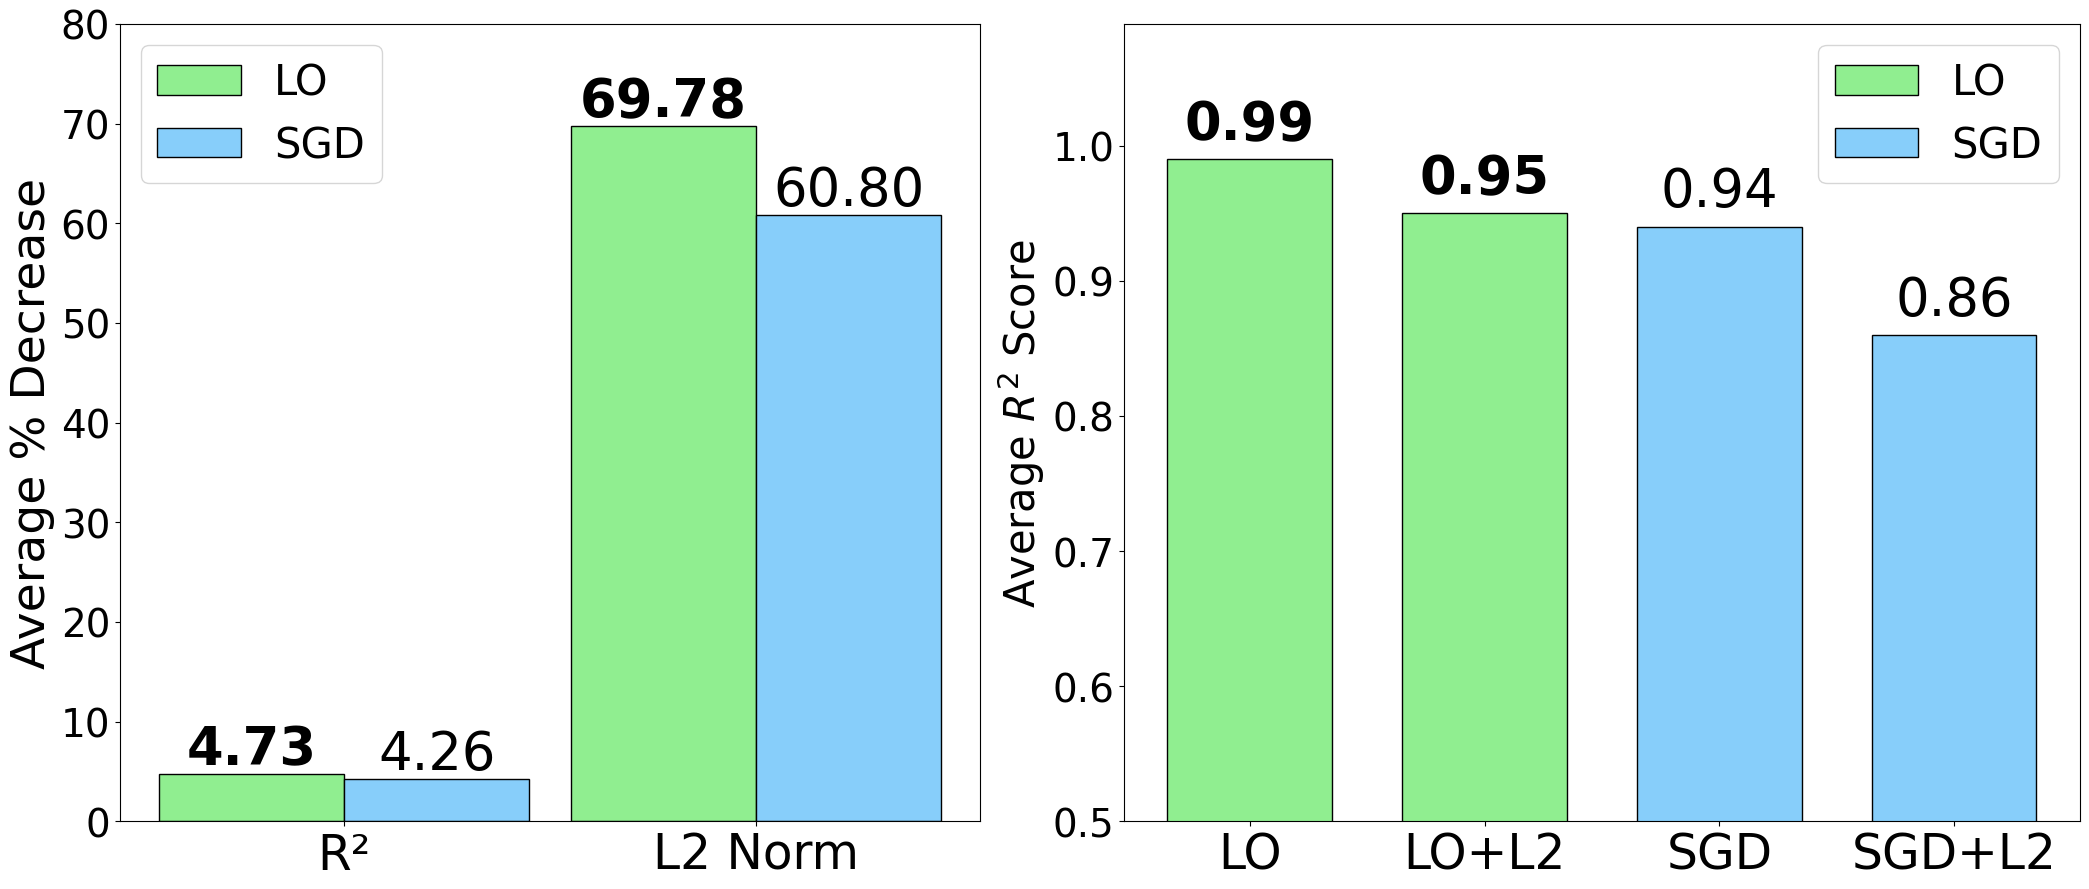

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

fig = plt.figure(figsize=(21, 9))
gs = GridSpec(1, 2, width_ratios=[0.9, 1])  # Left wider than right

# ==== Left plot: Average % Decrease ====
ax1 = fig.add_subplot(gs[0])
labels1 = ['R²', 'L2 Norm']
dmo_values1 = [4.73, 69.78]
sgd_values1 = [4.26, 60.80]

x1 = np.arange(len(labels1))
width = 0.45  # Increased bar width

ax1.bar(x1 - width/2, dmo_values1, width, label='LO', color='lightgreen', edgecolor='black')
ax1.bar(x1 + width/2, sgd_values1, width, label='SGD', color='lightskyblue', edgecolor='black')

ax1.set_ylabel('Average % Decrease', fontsize=34)
ax1.set_ylim(0, 80)
ax1.set_xticks(x1)
ax1.set_xticklabels(labels1, fontsize=35)
ax1.tick_params(axis='y', labelsize=28)
ax1.legend(loc='upper left', fontsize=30)

for i in range(len(x1)):
    ax1.text(x1[i] - width/2, dmo_values1[i] + 1, f'{dmo_values1[i]:.2f}', 
             ha='center', fontsize=38, weight='bold')
    ax1.text(x1[i] + width/2, sgd_values1[i] + 1, f'{sgd_values1[i]:.2f}', 
             ha='center', fontsize=38)

# ==== Right plot: Average R² Score ====
ax2 = fig.add_subplot(gs[1])
group_labels = [r'LO', r'LO+$L_2$', r'SGD', r'SGD+$L_2$']
values = [0.99, 0.95, 0.94, 0.86]
colors = ['lightgreen', 'lightgreen', 'lightskyblue', 'lightskyblue']

x2 = np.arange(len(group_labels))
width2 = 0.7  # Increased bar width

bars = ax2.bar(x2, values, width2, color=colors, edgecolor='black')

ax2.set_ylabel('Average $R^2$ Score', fontsize=30)
ax2.set_ylim(0.50, 1.09)
ax2.set_yticks(np.arange(0.5, 1.01, 0.1))
ax2.set_xticks(x2)
ax2.set_xticklabels(group_labels, fontsize=35)
ax2.tick_params(axis='y', labelsize=28)

legend_elements = [Patch(facecolor='lightgreen', edgecolor='black', label='LO'),
                   Patch(facecolor='lightskyblue', edgecolor='black', label='SGD')]
ax2.legend(handles=legend_elements, fontsize=30)

for i, value in enumerate(values):
    weight = 'bold' if i in [0, 1] else 'normal'
    ax2.text(x2[i], value + 0.015, f'{value:.2f}', ha='center', fontsize=38, weight=weight)

plt.tight_layout()
plt.show()
